In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import itertools

number_of_epochs = 20
batch_size = 64
learning_rate = 0.001
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
def load_and_preprocess_data():
    print("==== 1. Loading and Preprocessing Data ====")

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

    train_size = int(0.8 * len(full_train_dataset))
    val_size = len(full_train_dataset) - train_size
    train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    print(f"Train samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}, Test samples: {len(test_dataset)}")
    print("Data loaded and split successfully.")
    return train_loader, val_loader, test_loader

class MLP(nn.Module):
    def __init__(self, dropout_rate=0.0):
        super(MLP, self).__init__()
        input_size = 28 * 28
        hidden_size_1 = 512
        hidden_size_2 = 256
        num_classes = 10

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(input_size, hidden_size_1)
        self.dropout1 = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden_size_1, hidden_size_2)
        self.dropout2 = nn.Dropout(dropout_rate)
        self.fc3 = nn.Linear(hidden_size_2, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        x = self.dropout1(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout2(x)
        x = self.fc3(x)
        return x

def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_samples += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples
    return epoch_loss, epoch_accuracy

def evaluate_model(model, dataloader, criterion):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / total_samples
    accuracy = correct_predictions / total_samples
    return avg_loss, accuracy, all_labels, all_preds

def plot_confusion_matrix(cm, classes, title='Confusion Matrix', cmap=plt.cm.Blues):
    plt.figure(figsize=(8, 8))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

def plot_learning_curves(history, title):
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], label='Train Loss')
    plt.plot(epochs, history['val_loss'], label='Validation Loss')
    plt.title(f'{title} - Loss Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], label='Train Accuracy')
    plt.plot(epochs, history['val_acc'], label='Validation Accuracy')
    plt.title(f'{title} - Accuracy Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

def print_metrics(model_name, train_loss, val_loss, test_loss, train_acc, val_acc, test_acc, cm):
    print(f"==== {model_name} Final Metrics ====")
    print(f"Train Loss:      {train_loss:.4f} | Train Accuracy:      {train_acc:.4f}")
    print(f"Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.4f}")
    print(f"Test Loss:       {test_loss:.4f} | Test Accuracy:       {test_acc:.4f}")

    print("Confusion Matrix:")
    print(cm)
    plot_confusion_matrix(cm, classes=list(range(10)), title=f'{model_name} Confusion Matrix')

def analyze_learning(train_loss, val_loss, train_acc, val_acc):
    print("==== Learning Process Analysis ====")
    final_loss_diff = val_loss - train_loss
    final_acc_diff = train_acc - val_acc

    print(f"Final Loss Difference (Val - Train): {final_loss_diff:.4f}")
    print(f"Final Accuracy Difference (Train - Val): {final_acc_diff:.4f}")

    if final_loss_diff > 0.1 and final_acc_diff > 0.02:
        print("Analysis: **Overfitting** detected. The model performs significantly better on the training data than on the validation data. The loss gap is noticeable.")
    elif train_acc < 0.85:
        print("Analysis: **Underfitting** may be present. Both train and validation accuracy are low, suggesting the model is too simple or needs more training.")
    else:
        print("Analysis: Good generalization. Train and validation metrics are close, suggesting the model is learning effectively without severe overfitting.")

def run_experiment(model, criterion, optimizer, train_loader, val_loader, test_loader, num_epochs, name, weight_decay=0.0):
    print("="*50)
    print("Starting Experiment:",name)
    print("="*50)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc = 0.0
    best_model_state = None

    for epoch in range(1, num_epochs + 1):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _, _ = evaluate_model(model, val_loader, criterion)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch}/{num_epochs}: Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = model.state_dict()

    model.load_state_dict(best_model_state)
    train_loss, train_acc, _, _ = evaluate_model(model, train_loader, criterion)
    val_loss, val_acc, _, _ = evaluate_model(model, val_loader, criterion)
    test_loss, test_acc, true_labels, predictions = evaluate_model(model, test_loader, criterion)

    cm = confusion_matrix(true_labels, predictions)

    print_metrics(name, train_loss, val_loss, test_loss, train_acc, val_acc, test_acc, cm)
    plot_learning_curves(history, name)
    analyze_learning(train_loss, val_loss, train_acc, val_acc)

    return {'name': name, 'test_acc': test_acc, 'test_loss': test_loss, 'best_state': best_model_state}

In [ ]:
train_loader, val_loader, test_loader = load_and_preprocess_data()
criterion = nn.CrossEntropyLoss()

results = {}

==== 1. Loading and Preprocessing Data ====


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 495kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.89MB/s]

Train samples: 48000, Validation samples: 12000, Test samples: 10000
Data loaded and split successfully.


Starting Experiment: Base Model (SGD, No Reg)
Epoch 1/20: Train Loss: 2.2202, Val Loss: 2.1165, Train Acc: 0.3512, Val Acc: 0.5196
Epoch 2/20: Train Loss: 1.9620, Val Loss: 1.7782, Train Acc: 0.6010, Val Acc: 0.6609
Epoch 3/20: Train Loss: 1.5447, Val Loss: 1.3127, Train Acc: 0.7058, Val Acc: 0.7566
Epoch 4/20: Train Loss: 1.1223, Val Loss: 0.9582, Train Acc: 0.7779, Val Acc: 0.8047
Epoch 5/20: Train Loss: 0.8496, Val Loss: 0.7541, Train Acc: 0.8127, Val Acc: 0.8253
Epoch 6/20: Train Loss: 0.6949, Val Loss: 0.6348, Train Acc: 0.8333, Val Acc: 0.8464
Epoch 7/20: Train Loss: 0.6021, Val Loss: 0.5598, Train Acc: 0.8483, Val Acc: 0.8572
Epoch 8/20: Train Loss: 0.5410, Val Loss: 0.5086, Train Acc: 0.8595, Val Acc: 0.8676
Epoch 9/20: Train Loss: 0.4980, Val Loss: 0.4716, Train Acc: 0.8682, Val Acc: 0.8747
Epoch 10/20: Train Loss: 0.4661, Val Loss: 0.4437, Train Acc: 0.8753, Val Acc: 0.8787
Epoch 11/20: Train Loss: 0.4418, Val Loss: 0.4237, Train Acc: 0.8797, Val Acc: 0.8808
Epoch 12/20: Trai

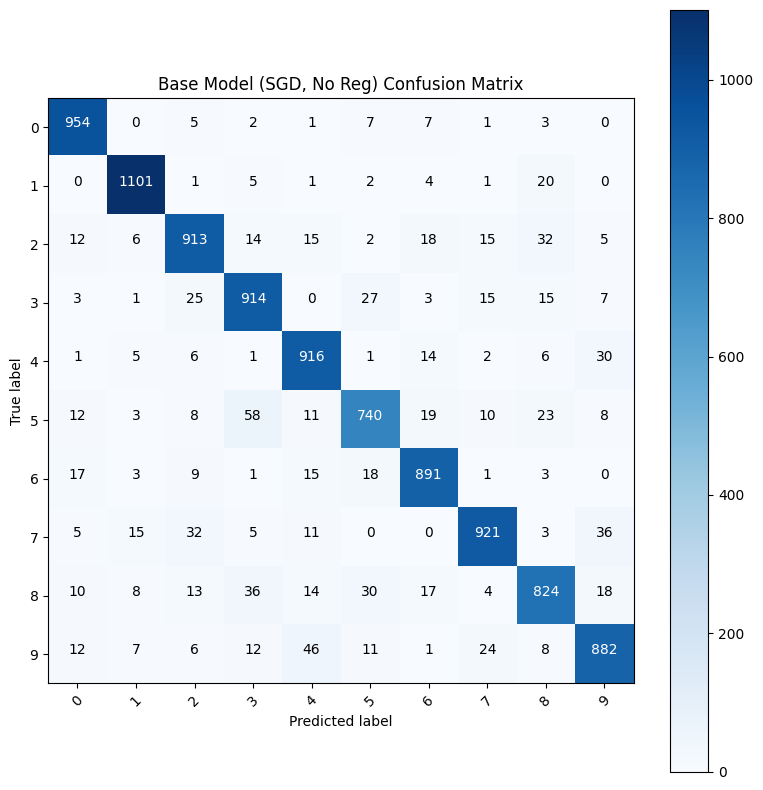

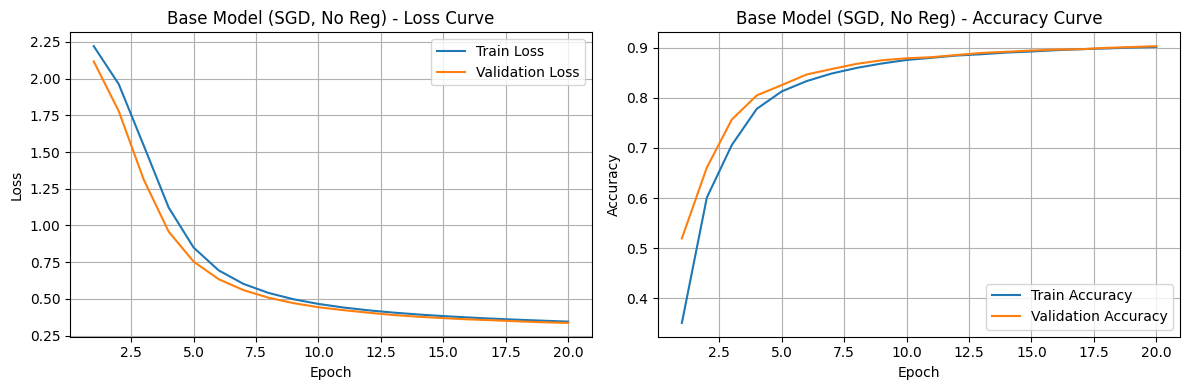

==== Learning Process Analysis ====
Final Loss Difference (Val - Train): -0.0064
Final Accuracy Difference (Train - Val): -0.0007
Analysis: Good generalization. Train and validation metrics are close, suggesting the model is learning effectively without severe overfitting.


In [ ]:
base_model = MLP(dropout_rate=0.0).to(device)
base_optimizer = optim.SGD(base_model.parameters(), lr=learning_rate)

base_result = run_experiment(base_model, criterion, base_optimizer,
                              train_loader, val_loader, test_loader,
                              number_of_epochs, "Base Model (SGD, No Reg)")
results['base_model'] = base_result

Starting Experiment: Regularized Model (Adam, L2, Dropout=0.3)
Epoch 1/20: Train Loss: 0.4130, Val Loss: 0.1845, Train Acc: 0.8704, Val Acc: 0.9437
Epoch 2/20: Train Loss: 0.2270, Val Loss: 0.1425, Train Acc: 0.9309, Val Acc: 0.9548
Epoch 3/20: Train Loss: 0.1865, Val Loss: 0.1286, Train Acc: 0.9423, Val Acc: 0.9608
Epoch 4/20: Train Loss: 0.1676, Val Loss: 0.1303, Train Acc: 0.9483, Val Acc: 0.9574
Epoch 5/20: Train Loss: 0.1553, Val Loss: 0.0929, Train Acc: 0.9523, Val Acc: 0.9727
Epoch 6/20: Train Loss: 0.1407, Val Loss: 0.1093, Train Acc: 0.9563, Val Acc: 0.9656
Epoch 7/20: Train Loss: 0.1334, Val Loss: 0.1057, Train Acc: 0.9586, Val Acc: 0.9679
Epoch 8/20: Train Loss: 0.1304, Val Loss: 0.1026, Train Acc: 0.9596, Val Acc: 0.9690
Epoch 9/20: Train Loss: 0.1195, Val Loss: 0.1026, Train Acc: 0.9631, Val Acc: 0.9686
Epoch 10/20: Train Loss: 0.1237, Val Loss: 0.0845, Train Acc: 0.9615, Val Acc: 0.9754
Epoch 11/20: Train Loss: 0.1137, Val Loss: 0.0884, Train Acc: 0.9641, Val Acc: 0.9745


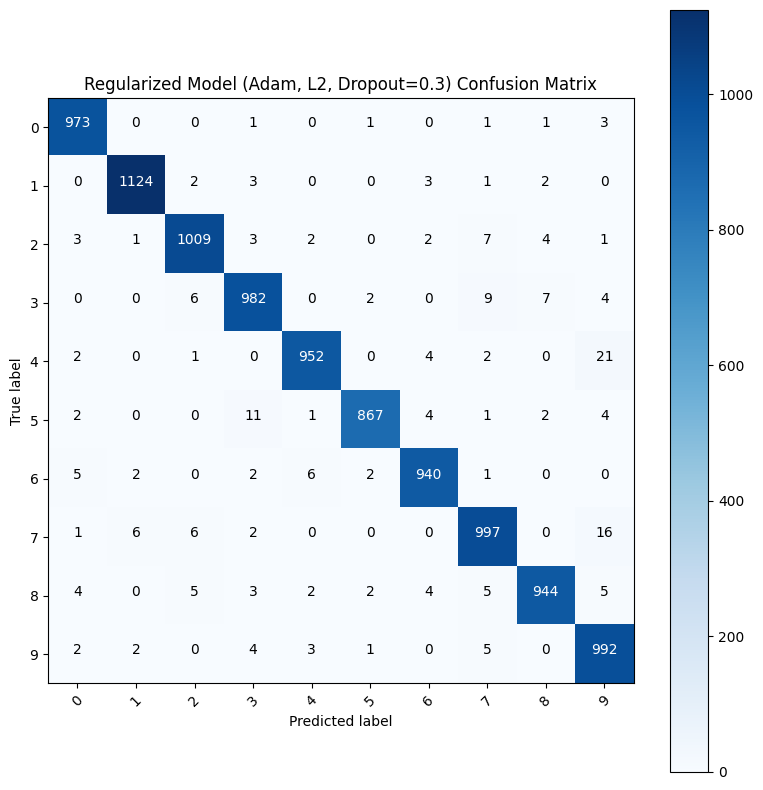

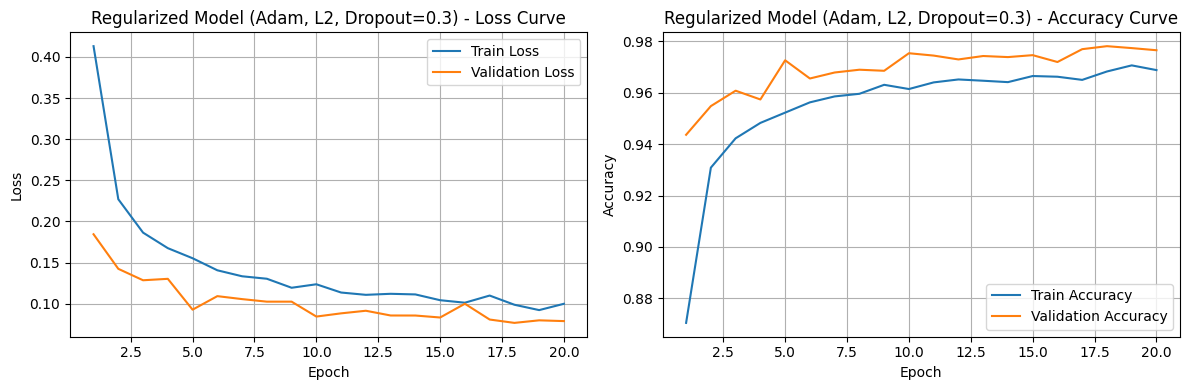

==== Learning Process Analysis ====
Final Loss Difference (Val - Train): 0.0376
Final Accuracy Difference (Train - Val): 0.0104
Analysis: Good generalization. Train and validation metrics are close, suggesting the model is learning effectively without severe overfitting.


In [ ]:
reg_model = MLP(dropout_rate=0.3).to(device)
reg_optimizer = optim.Adam(reg_model.parameters(), lr=learning_rate, weight_decay=1e-4)

reg_result = run_experiment(reg_model, criterion, reg_optimizer,
                            train_loader, val_loader, test_loader,
                            number_of_epochs, "Regularized Model (Adam, L2, Dropout=0.3)")
results['regularized_model'] = reg_result

با مقایسه‌ی روند یادگیری دو مدل، واضح است که مدل regularized با خطای خیلی کمتر و دقت خیلی بیشتر، روند یادگیری بهتری را تجربه کرده است. البته خطا و دقت validation طبق نمودار یادگیری مدل regularized به صورت پیوسته بهبود پیدا نکردند و هنگام یادگیری، گاهی دچار پس‌رفت شده اند. اما در نهایت روند بهبود کلی برقرار بوده و پس‌رفت‌ها موقتی می‌باشند.

Starting Experiment: Optimizer Comparison: Adam (No Reg)
Epoch 1/20: Train Loss: 0.3279, Val Loss: 0.2213, Train Acc: 0.9004, Val Acc: 0.9280
Epoch 2/20: Train Loss: 0.1484, Val Loss: 0.1394, Train Acc: 0.9547, Val Acc: 0.9571
Epoch 3/20: Train Loss: 0.1138, Val Loss: 0.1170, Train Acc: 0.9640, Val Acc: 0.9639
Epoch 4/20: Train Loss: 0.0883, Val Loss: 0.1028, Train Acc: 0.9718, Val Acc: 0.9700
Epoch 5/20: Train Loss: 0.0762, Val Loss: 0.1076, Train Acc: 0.9753, Val Acc: 0.9680
Epoch 6/20: Train Loss: 0.0682, Val Loss: 0.0971, Train Acc: 0.9782, Val Acc: 0.9696
Epoch 7/20: Train Loss: 0.0569, Val Loss: 0.1296, Train Acc: 0.9811, Val Acc: 0.9620
Epoch 8/20: Train Loss: 0.0500, Val Loss: 0.1019, Train Acc: 0.9838, Val Acc: 0.9721
Epoch 9/20: Train Loss: 0.0456, Val Loss: 0.1110, Train Acc: 0.9850, Val Acc: 0.9704
Epoch 10/20: Train Loss: 0.0381, Val Loss: 0.1373, Train Acc: 0.9872, Val Acc: 0.9650
Epoch 11/20: Train Loss: 0.0375, Val Loss: 0.1170, Train Acc: 0.9874, Val Acc: 0.9714
Epoch 

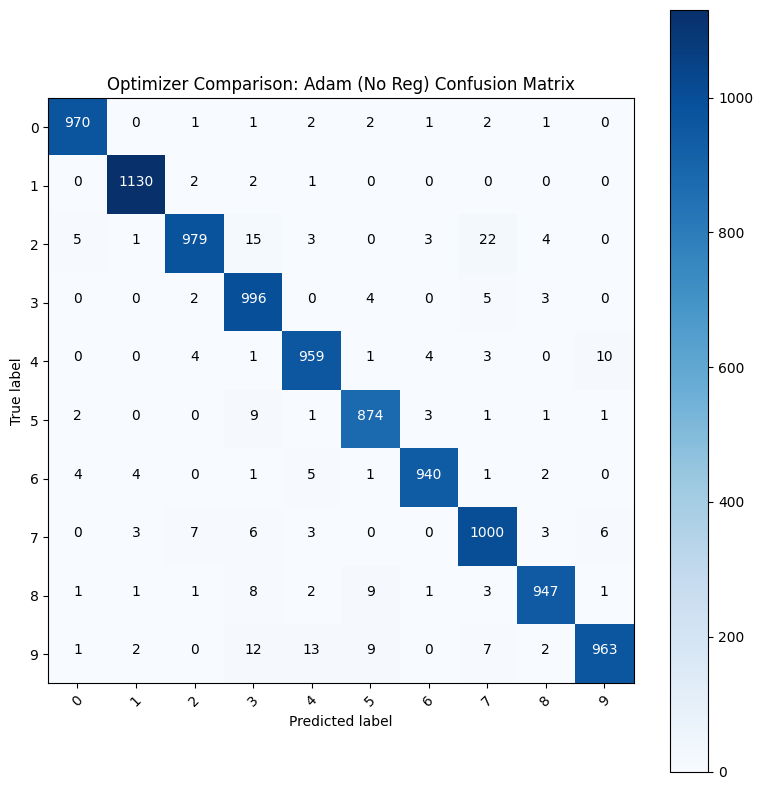

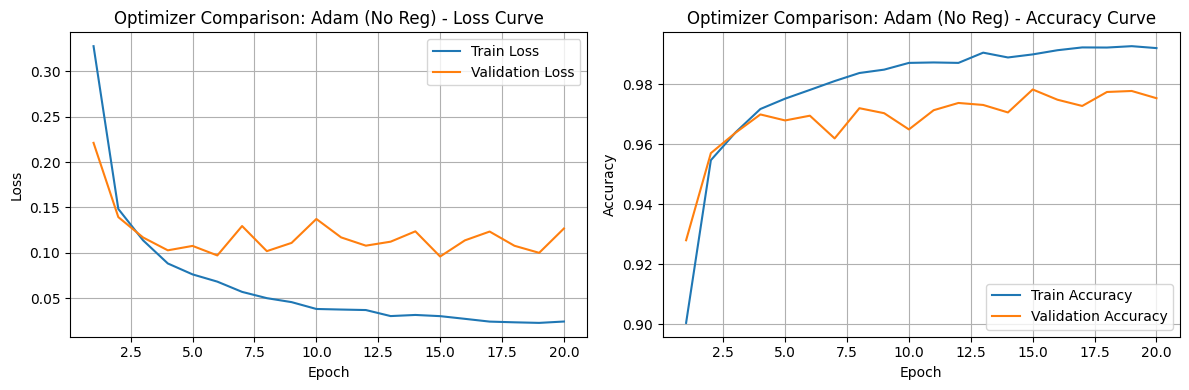

==== Learning Process Analysis ====
Final Loss Difference (Val - Train): 0.1046
Final Accuracy Difference (Train - Val): 0.0174
Analysis: Good generalization. Train and validation metrics are close, suggesting the model is learning effectively without severe overfitting.


In [ ]:
adam_model = MLP(dropout_rate=0.0).to(device)
adam_optimizer = optim.Adam(adam_model.parameters(), lr=learning_rate)

adam_result = run_experiment(adam_model, criterion, adam_optimizer,
                              train_loader, val_loader, test_loader,
                              number_of_epochs, "Optimizer Comparison: Adam (No Reg)")
results['adam_model'] = adam_result

مدلی که از روش dropout استفاده می‌کند، با سرعت بالاتری به مقادیر نهایی روند یادگیری می‌رسند و دوره یا epoch های کمتری برای converge کردن نیاز دارد، اما در مقابل و همانطور که از نمودار روند یادگیری آن پیداست، دقت و خطای validation در دوره‌های انتهایی دچار نوسان شده و پیش‌رفت آن متوقف شده است. همچنین قابل توجه است که دقت این مدل روی داده‌های تست کمتر از مدل regularized است.

Starting Experiment: Optimizer Comparison: RMSprop
Epoch 1/20: Train Loss: 0.3944, Val Loss: 0.2107, Train Acc: 0.8858, Val Acc: 0.9337
Epoch 2/20: Train Loss: 0.1590, Val Loss: 0.1487, Train Acc: 0.9513, Val Acc: 0.9541
Epoch 3/20: Train Loss: 0.1149, Val Loss: 0.1013, Train Acc: 0.9645, Val Acc: 0.9704
Epoch 4/20: Train Loss: 0.0928, Val Loss: 0.1441, Train Acc: 0.9704, Val Acc: 0.9559
Epoch 5/20: Train Loss: 0.0769, Val Loss: 0.0883, Train Acc: 0.9750, Val Acc: 0.9719
Epoch 6/20: Train Loss: 0.0654, Val Loss: 0.0970, Train Acc: 0.9794, Val Acc: 0.9725
Epoch 7/20: Train Loss: 0.0571, Val Loss: 0.1036, Train Acc: 0.9818, Val Acc: 0.9700
Epoch 8/20: Train Loss: 0.0507, Val Loss: 0.0887, Train Acc: 0.9837, Val Acc: 0.9760
Epoch 9/20: Train Loss: 0.0468, Val Loss: 0.1178, Train Acc: 0.9849, Val Acc: 0.9657
Epoch 10/20: Train Loss: 0.0409, Val Loss: 0.1128, Train Acc: 0.9859, Val Acc: 0.9688
Epoch 11/20: Train Loss: 0.0391, Val Loss: 0.1108, Train Acc: 0.9875, Val Acc: 0.9718
Epoch 12/20:

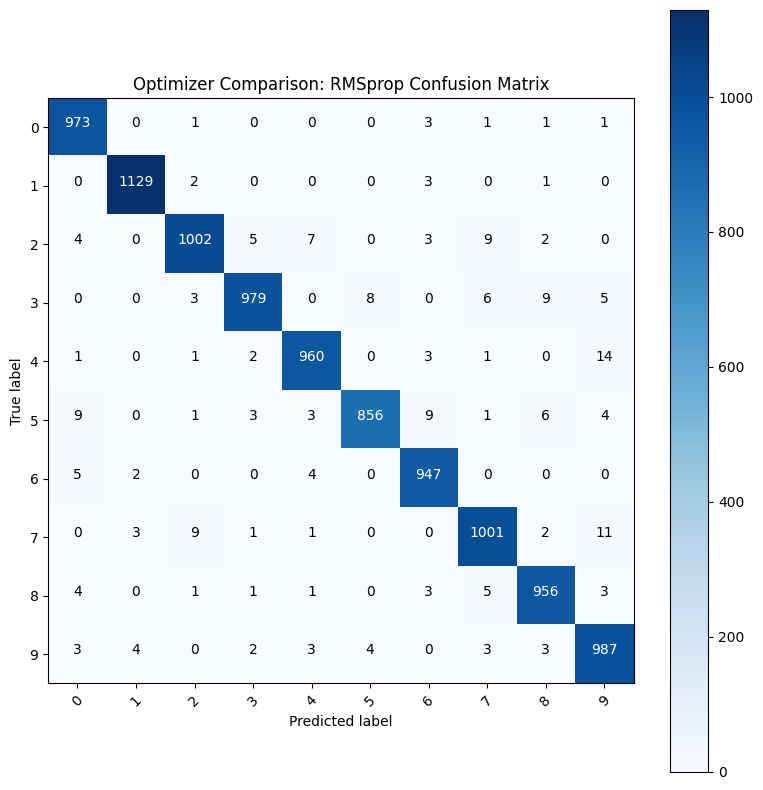

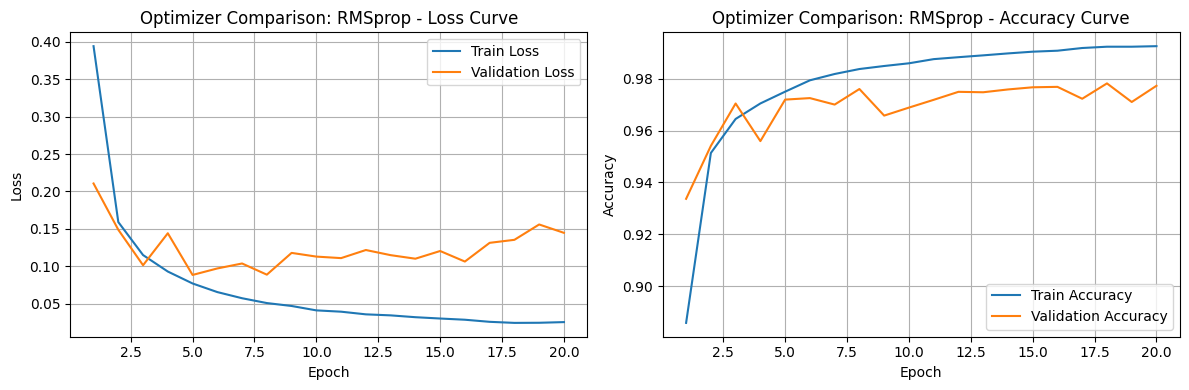

==== Learning Process Analysis ====
Final Loss Difference (Val - Train): 0.1238
Final Accuracy Difference (Train - Val): 0.0166
Analysis: Good generalization. Train and validation metrics are close, suggesting the model is learning effectively without severe overfitting.


In [ ]:
rmsprop_model = MLP(dropout_rate=0.0).to(device)
rmsprop_optimizer = optim.RMSprop(rmsprop_model.parameters(), lr=0.001)

rmsprop_result = run_experiment(rmsprop_model, criterion, rmsprop_optimizer,
                                train_loader, val_loader, test_loader,
                                number_of_epochs, "Optimizer Comparison: RMSprop")
results['rmsprop_model'] = rmsprop_result

یک مدل RMS نیز برای مقایسه قرار داده شده است. این مدل روند یادگیری مشابهی با مدل regularized دارد.

In [ ]:
print("!"*70)
print("!!! Final Summary and Best Model Report !!!")
print("!"*70)

best_accuracy = 0.0
best_model_name = ""

for key, result in results.items():
    print(f"{result['name']}: Test Accuracy = {result['test_acc']:.4f}, Test Loss = {result['test_loss']:.4f}")
    if result['test_acc'] > best_accuracy:
        best_accuracy = result['test_acc']
        best_model_name = result['name']

print(f"==== Conclusion ====")
print(f"The **Best Performing Model** is: **{best_model_name}**")
print(f"With a Test Accuracy of: **{best_accuracy:.4f}**")

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!!! Final Summary and Best Model Report !!!
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
Base Model (SGD, No Reg): Test Accuracy = 0.9056, Test Loss = 0.3301
Regularized Model (Adam, L2, Dropout=0.3): Test Accuracy = 0.9780, Test Loss = 0.0733
Optimizer Comparison: Adam (No Reg): Test Accuracy = 0.9758, Test Loss = 0.1139
Optimizer Comparison: RMSprop: Test Accuracy = 0.9790, Test Loss = 0.1285
==== Conclusion ====
The **Best Performing Model** is: **Optimizer Comparison: RMSprop**
With a Test Accuracy of: **0.9790**
